# Demo EDM

## Imports

In [30]:
import torch
import cv2
import matplotlib.cm as cm
from src.utils.plotting import make_matching_figure
import random
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

## Setup

In [102]:
from src.edm import EDM
from src.config.default import get_cfg_defaults
from src.utils.misc import lower_config

config = get_cfg_defaults()
data_cfg_path = "configs/data/megadepth_test_1500.py"
main_cfg_path = "configs/edm/outdoor/edm_base.py"
config.merge_from_file(main_cfg_path)
config.merge_from_file(data_cfg_path)

W, H = 640, 480
config.EDM.COARSE.MCONF_THR = 0.2
config.EDM.COARSE.BORDER_RM = 2

_config = lower_config(config)
matcher = EDM(config=_config["edm"])
state_dict = torch.load("weights/edm_outdoor.ckpt", map_location=torch.device('cpu'))["state_dict"]
matcher.load_state_dict(state_dict)
matcher = matcher.eval()

## Feature matching

In [112]:
def feature_matching(pair, match_confidence_threshold, number_of_matches, draw = True):
    # Load images
    img0_bgr = cv2.imread(pair[0])
    img1_bgr = cv2.imread(pair[1])

    # For draw
    img0_rgb = img0_bgr[:, :, ::-1]
    img1_rgb = img1_bgr[:, :, ::-1]
    img0_rgb = cv2.resize(img0_rgb, (W, H))
    img1_rgb = cv2.resize(img1_rgb, (W, H))

    # For inference
    img0_raw = cv2.cvtColor(img0_bgr, cv2.COLOR_BGR2GRAY)
    img1_raw = cv2.cvtColor(img1_bgr, cv2.COLOR_BGR2GRAY)
    img0_raw = cv2.resize(img0_raw, (W, H))
    img1_raw = cv2.resize(img1_raw, (W, H))

    img0 = torch.from_numpy(img0_raw)[None][None].cpu() / 255.
    img1 = torch.from_numpy(img1_raw)[None][None].cpu() / 255.
    batch = {'image0': img0, 'image1': img1}

    # Inference with EDM and get prediction
    with torch.no_grad():
        matcher(batch)

    mkpts0 = batch['mkpts0_f'].cpu().numpy()
    mkpts1 = batch['mkpts1_f'].cpu().numpy()
    mconf = batch['mconf'].cpu().numpy()

    color = np.stack([1 - mconf, mconf, np.zeros_like(mconf)], axis=1)

    keep = mconf > match_confidence_threshold
    mkpts0 = mkpts0[keep]
    mkpts1 = mkpts1[keep]
    color = color[keep]
    
    # Draw
    if draw and len(mkpts0) >= number_of_matches:
        text = [f"Matches: {len(mkpts0)}"]
        make_matching_figure(img0_rgb, img1_rgb, mkpts0, mkpts1, color, text=text)
        plt.show()
    

    return mkpts0, mkpts1, mconf


## Omography

In [129]:
def omography(pair, match_confidence_threshold, number_of_matches):
    # Load images
    img0_bgr = cv2.imread(pair[0])
    img1_bgr = cv2.imread(pair[1])

    # Resize for display
    img0_rgb = cv2.cvtColor(cv2.resize(img0_bgr, (W, H)), cv2.COLOR_BGR2RGB)
    img1_rgb = cv2.cvtColor(cv2.resize(img1_bgr, (W, H)), cv2.COLOR_BGR2RGB)

    # Prepare grayscale for matcher
    img0_raw = cv2.cvtColor(cv2.resize(img0_bgr, (W, H)), cv2.COLOR_BGR2GRAY)
    img1_raw = cv2.cvtColor(cv2.resize(img1_bgr, (W, H)), cv2.COLOR_BGR2GRAY)

    img0 = torch.from_numpy(img0_raw)[None, None].cpu() / 255.
    img1 = torch.from_numpy(img1_raw)[None, None].cpu() / 255.
    batch = {'image0': img0, 'image1': img1}

    # Inference with EDM
    with torch.no_grad():
        matcher(batch)

    mkpts0 = batch['mkpts0_f'].cpu().numpy()
    mkpts1 = batch['mkpts1_f'].cpu().numpy()
    mconf = batch['mconf'].cpu().numpy()

    # Filter by confidence
    keep = mconf > match_confidence_threshold
    mkpts0 = mkpts0[keep]
    mkpts1 = mkpts1[keep]

    if len(mkpts0) >= number_of_matches and len(mkpts1) >= number_of_matches:
        # Calcola omografia
        H_matrix, mask = cv2.findHomography(mkpts0, mkpts1, cv2.RANSAC)

        # Sovrapponi img0 su img1
        height, width = img1_rgb.shape[:2]
        warped_img0 = cv2.warpPerspective(img0_rgb, H_matrix, (width, height))

        # Crea overlay
        overlay = cv2.addWeighted(img1_rgb, 0.5, warped_img0, 0.5, 0)

        # Disegna bordo rosso direttamente sull'overlay
        h0, w0 = img0_rgb.shape[:2]
        corners = np.array([[0,0], [w0,0], [w0,h0], [0,h0]], dtype=np.float32).reshape(-1,1,2)
        transformed_corners = cv2.perspectiveTransform(corners, H_matrix)
        cv2.polylines(overlay, [np.int32(transformed_corners)], isClosed=True, color=(255,0,0), thickness=5)

        # Mostra immagine
        plt.figure(figsize=(10, 8))
        plt.imshow(overlay)
        plt.axis('off')
        plt.show()

        return overlay
    else:
        return img1_rgb


## Run example

In [133]:
# Select random claim
claims_directory = "../Claims"
claim = random.choice([x for x in Path(claims_directory).iterdir() if x.is_dir()])

images = [x for x in Path(claim).iterdir()]

combinations = []
for idx_1 in range(len(images)):
    for idx_2 in range(idx_1+1, len(images)):
        combinations.append((images[idx_1], images[idx_2]))


print(f"Claim {str(claim).replace('../Claims/claim_', '')}, contains {len(images)} images ({len(combinations)} combinations).")

Claim 143, contains 37 images (666 combinations).


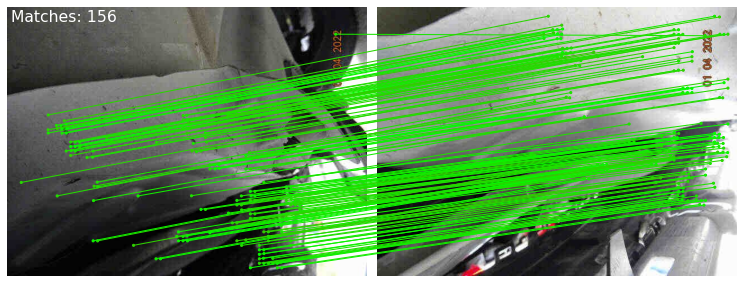

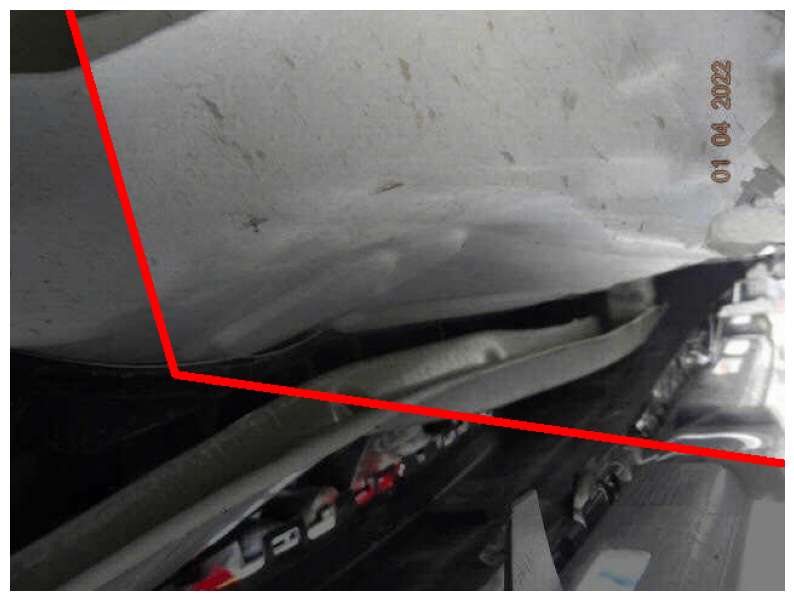

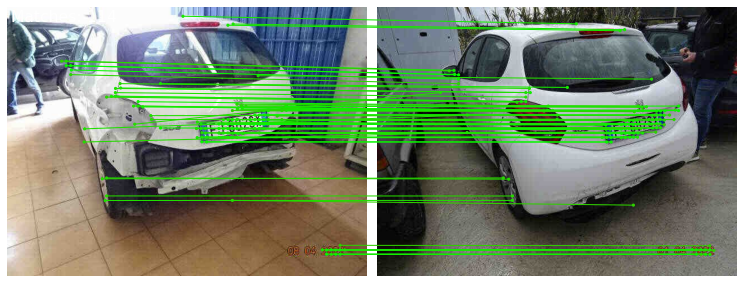

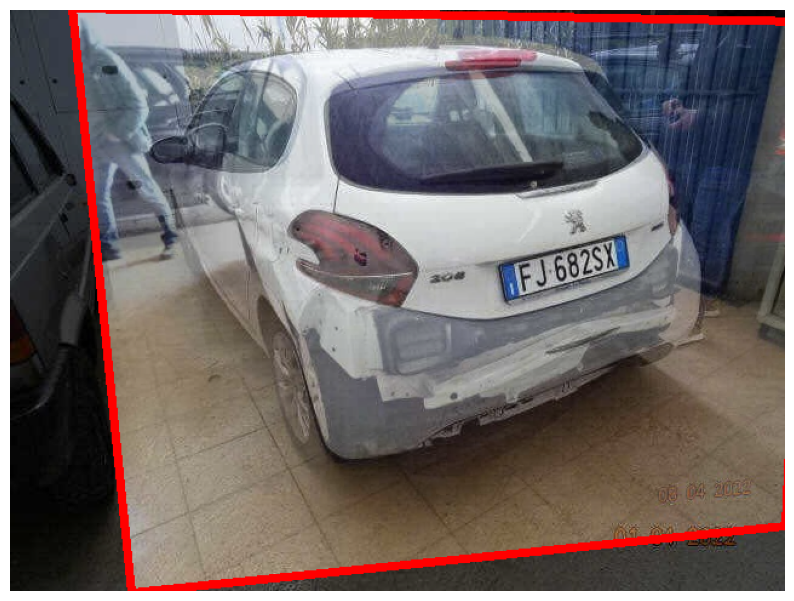

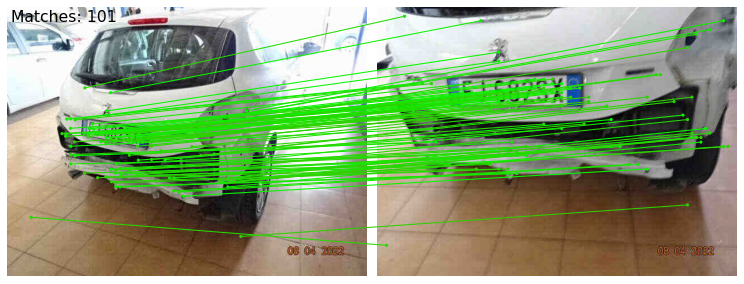

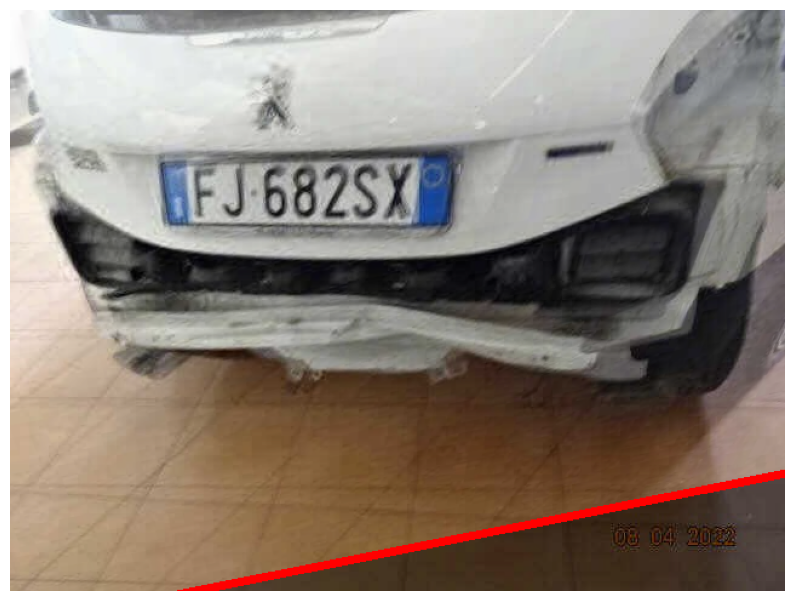

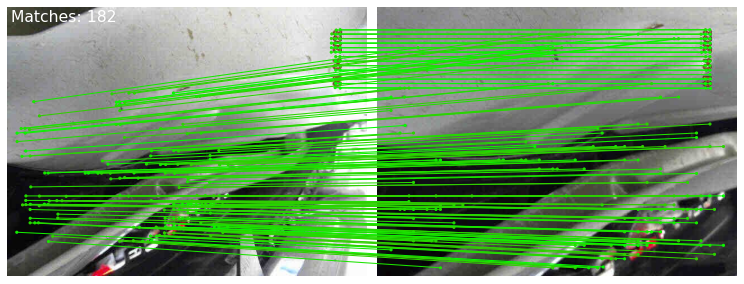

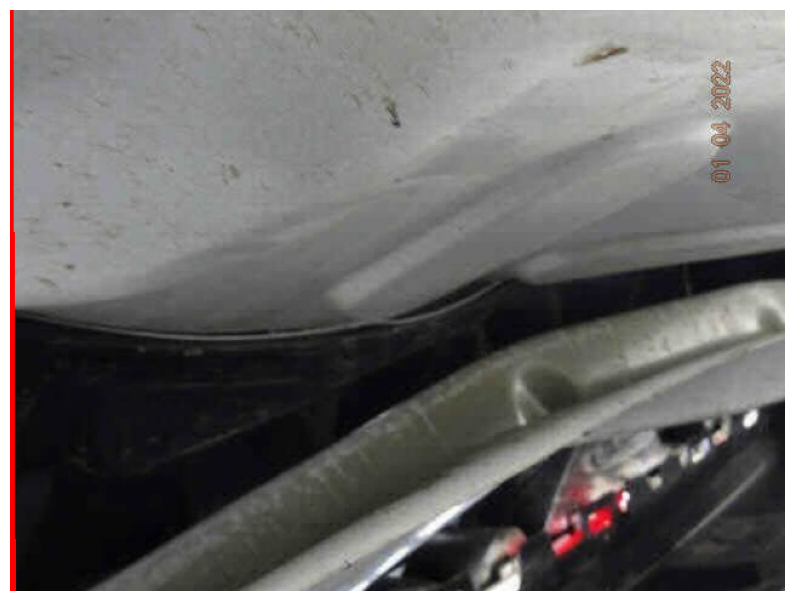

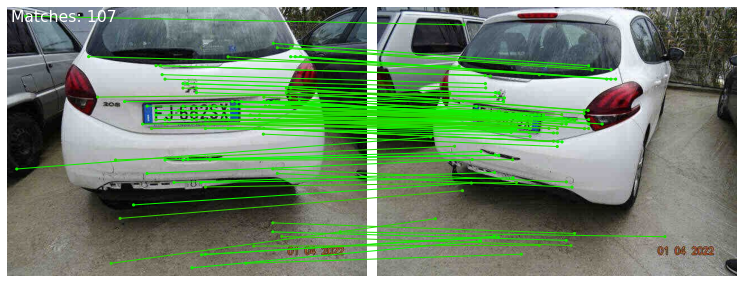

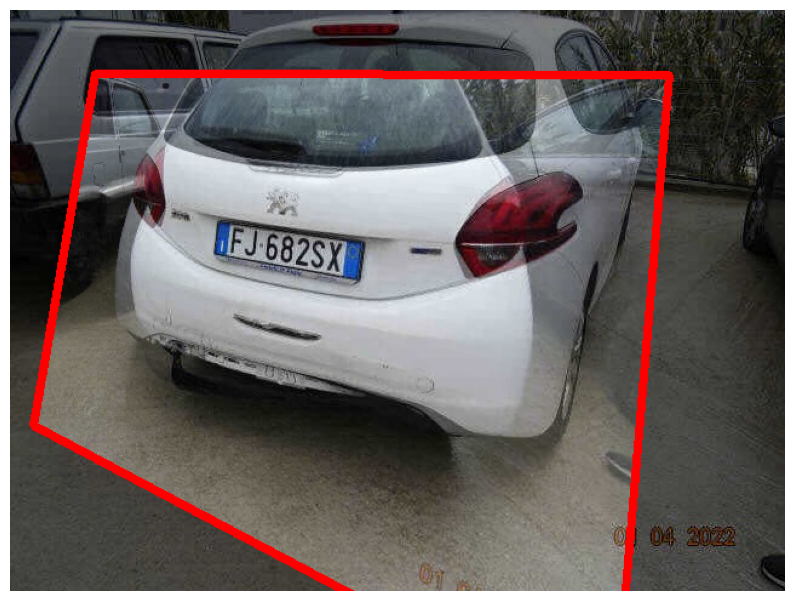

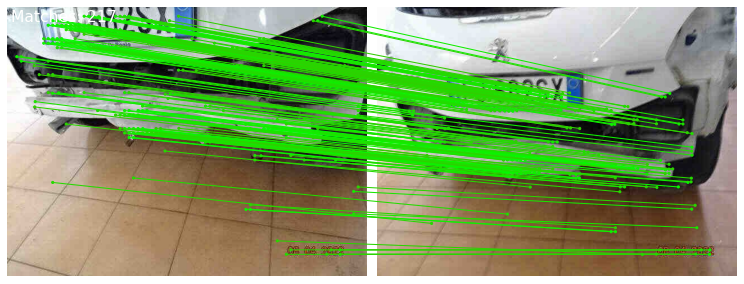

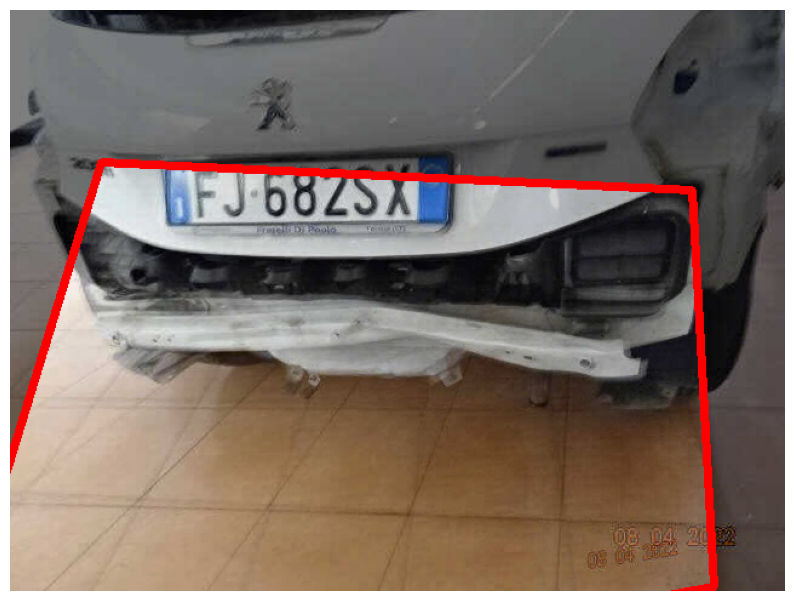

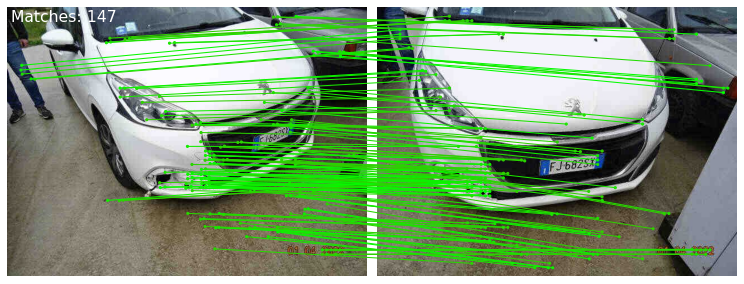

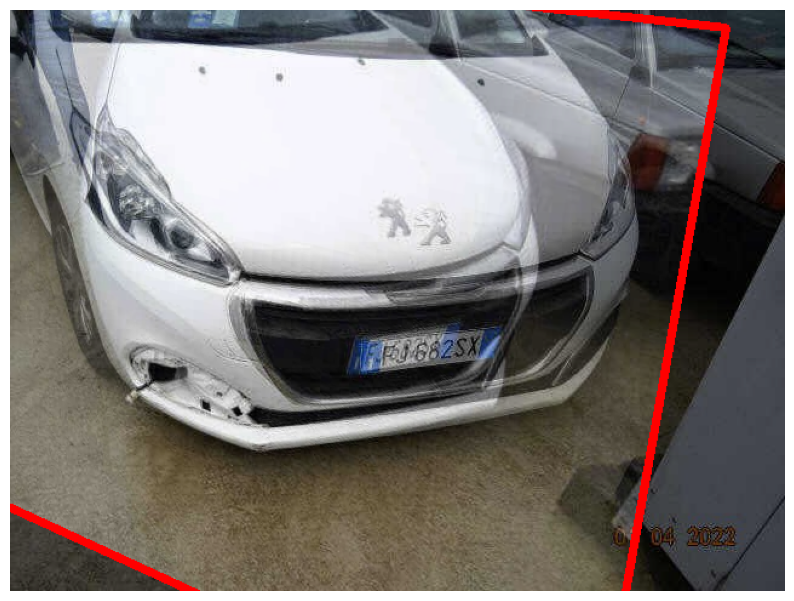

In [134]:
# Parameters
match_confidence_treshold = 0.8
number_of_matches = 100


for pair in combinations:
    feature_matching(pair, match_confidence_treshold, number_of_matches)
    omography(pair, match_confidence_treshold, number_of_matches)
